Here we begin with Modul 1

My Dataset is called: Switzerland Greenhouse Gas Dataset.

It contains measurements for various greenhouse gases (air pollutants) like O3 (ozon), SO2 (sulfur dioxide) and NOX (nitrogen oxides = No2 & NO together) collected from 2021 to 2023 for the whole of Switzerland, as well as the geodata variables longitude	and latitude (we need it for M3).

And also contains the measured concentration for particulate matter (Feinstaub) where PM10 means Particulate Matter ≤ 10 μm (e.g. pollen, dust) and PM2.5 means Particulate Matter ≤ 2.5 μm (somke, soot).

Unit of measurement is for all the pollutants the same: µg/m³

The Dataset is huge consisting of only 7 columns but 1'048'576 rows (one is the header).

Source: Data records for individual pollutants were obtained from
Federal Office for the Environment (FOEN). (Bundesamt für Umwelt BAFU: Treibhausgasemissionen der Schweiz.)

Disclaimer: This excel is actually not downloadable on the BAFU website.
The dataset is huge and takes 4 min to load.


In [5]:
# Upload the local data file to colab
from google.colab import files
uploaded = files.upload()

Saving Switzerland Greenhouse Gas Dataset.xlsx to Switzerland Greenhouse Gas Dataset (1).xlsx


In [7]:
import numpy as np #this is where all the lin.alg. stuff is
import pandas as pd #needed to load my dataset
import matplotlib.pyplot as plt #needed to plot
import seaborn as sns #another plotting package

In [ ]:
df = pd.read_excel("Switzerland Greenhouse Gas Dataset.xlsx")

df.head()

,Longitude,Latitude,O3,PM10,PM2.5,SO2,NOX
0,2684550,1295850,145,7.1,5.4,0.1,4
1,2684550,1295750,145,7.1,5.5,0.1,4
2,2684650,1295750,145,7.1,5.5,0.1,4
3,2684450,1295650,145,7.1,5.5,0.1,4
4,2684550,1295650,145,7.2,5.5,0.1,4


Now I want to check that everything imported correctly:

In [8]:
# Check the column names
print(df.columns.tolist()) #tolist is a method used to convert specialized data structures (like arrays or data series) into standard Python lists, it is from pandas

# Check the number of rows and columns
print(df.shape)

# Check the data types
print(df.dtypes)

# Check for missing values
print(df.isnull().sum())

['Longitude', 'Latitude', 'O3', 'PM10', 'PM2.5', 'SO2', 'NOX']
(1048575, 7)
Longitude      int64
Latitude       int64
O3             int64
PM10         float64
PM2.5        float64
SO2          float64
NOX            int64
dtype: object
Longitude    0
Latitude     0
O3           0
PM10         0
PM2.5        0
SO2          0
NOX          0
dtype: int64


We don't have missing data so we have nothing to remove. And also don't have NA/NaN values to fill.
As I know the data is complete with no issues, I will now continue with the visualisation part.

Bte since my file is quite large (loads slowly), I could read the it in chunks instead of loading everything into memory at once:

In [9]:
# pd.read_excel does not support 'chunksize'.
# To read in chunks, I would first need to convert the Excel file to a CSV file:
df.to_csv("Switzerland Greenhouse Gas Dataset.csv", index=False)

# Then I can read it in chunks like this:
chunksize = 100_000
for chunk in pd.read_csv(
    "Switzerland Greenhouse Gas Dataset.csv",
    chunksize=chunksize
):
    print(chunk.head())
    break
# This reads the first 100,000 rows but displays only the first five, without
# loading the entire dataset.

   Longitude  Latitude   O3  PM10  PM2.5  SO2  NOX
0    2684550   1295850  145   7.1    5.4  0.1    4
1    2684550   1295750  145   7.1    5.5  0.1    4
2    2684650   1295750  145   7.1    5.5  0.1    4
3    2684450   1295650  145   7.1    5.5  0.1    4
4    2684550   1295650  145   7.2    5.5  0.1    4


We want to plot 3 histograms with a legend in the same graph for the 3 different pollutantsa dn the 2 pm.

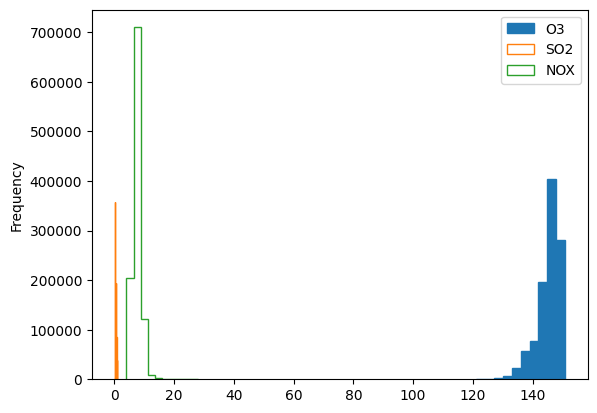

In [29]:
df['O3'].plot(kind="hist",fill=True,histtype='step',label='O3')
df['SO2'].plot(kind="hist",fill=False,histtype='step',label='SO2')
df['NOX'].plot(kind="hist",fill=False,histtype='step',label='NOX')
plt.legend()
plt.show()

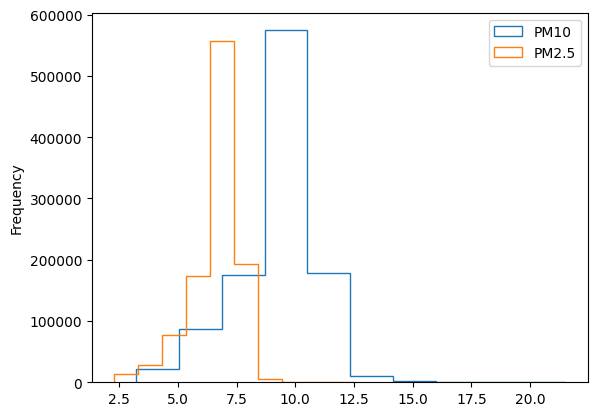

In [11]:
df['PM10'].plot(kind="hist",fill=False,histtype='step',label='PM10')
df['PM2.5'].plot(kind="hist",fill=False,histtype='step',label='PM2.5')
plt.legend()
plt.show()

But is this a useful visualisation? Not really, it only shows us how often each concentration appears in the dataset seperated into the 3 different pollutants ans into the two PM. This does not give us a visual intuition of the dataset.

To get a good visual intuition of the dataset let's create histograms of the pollutant concentrations and for this we create one histogram for each pollutant but in one plot.
Why do I create histograms of pollutant concentrations?
Because it helps to illustrate the following question:
Are most measurements low, or are there a few very high values?
And it helps understand distributions, skewness and possible outliers.



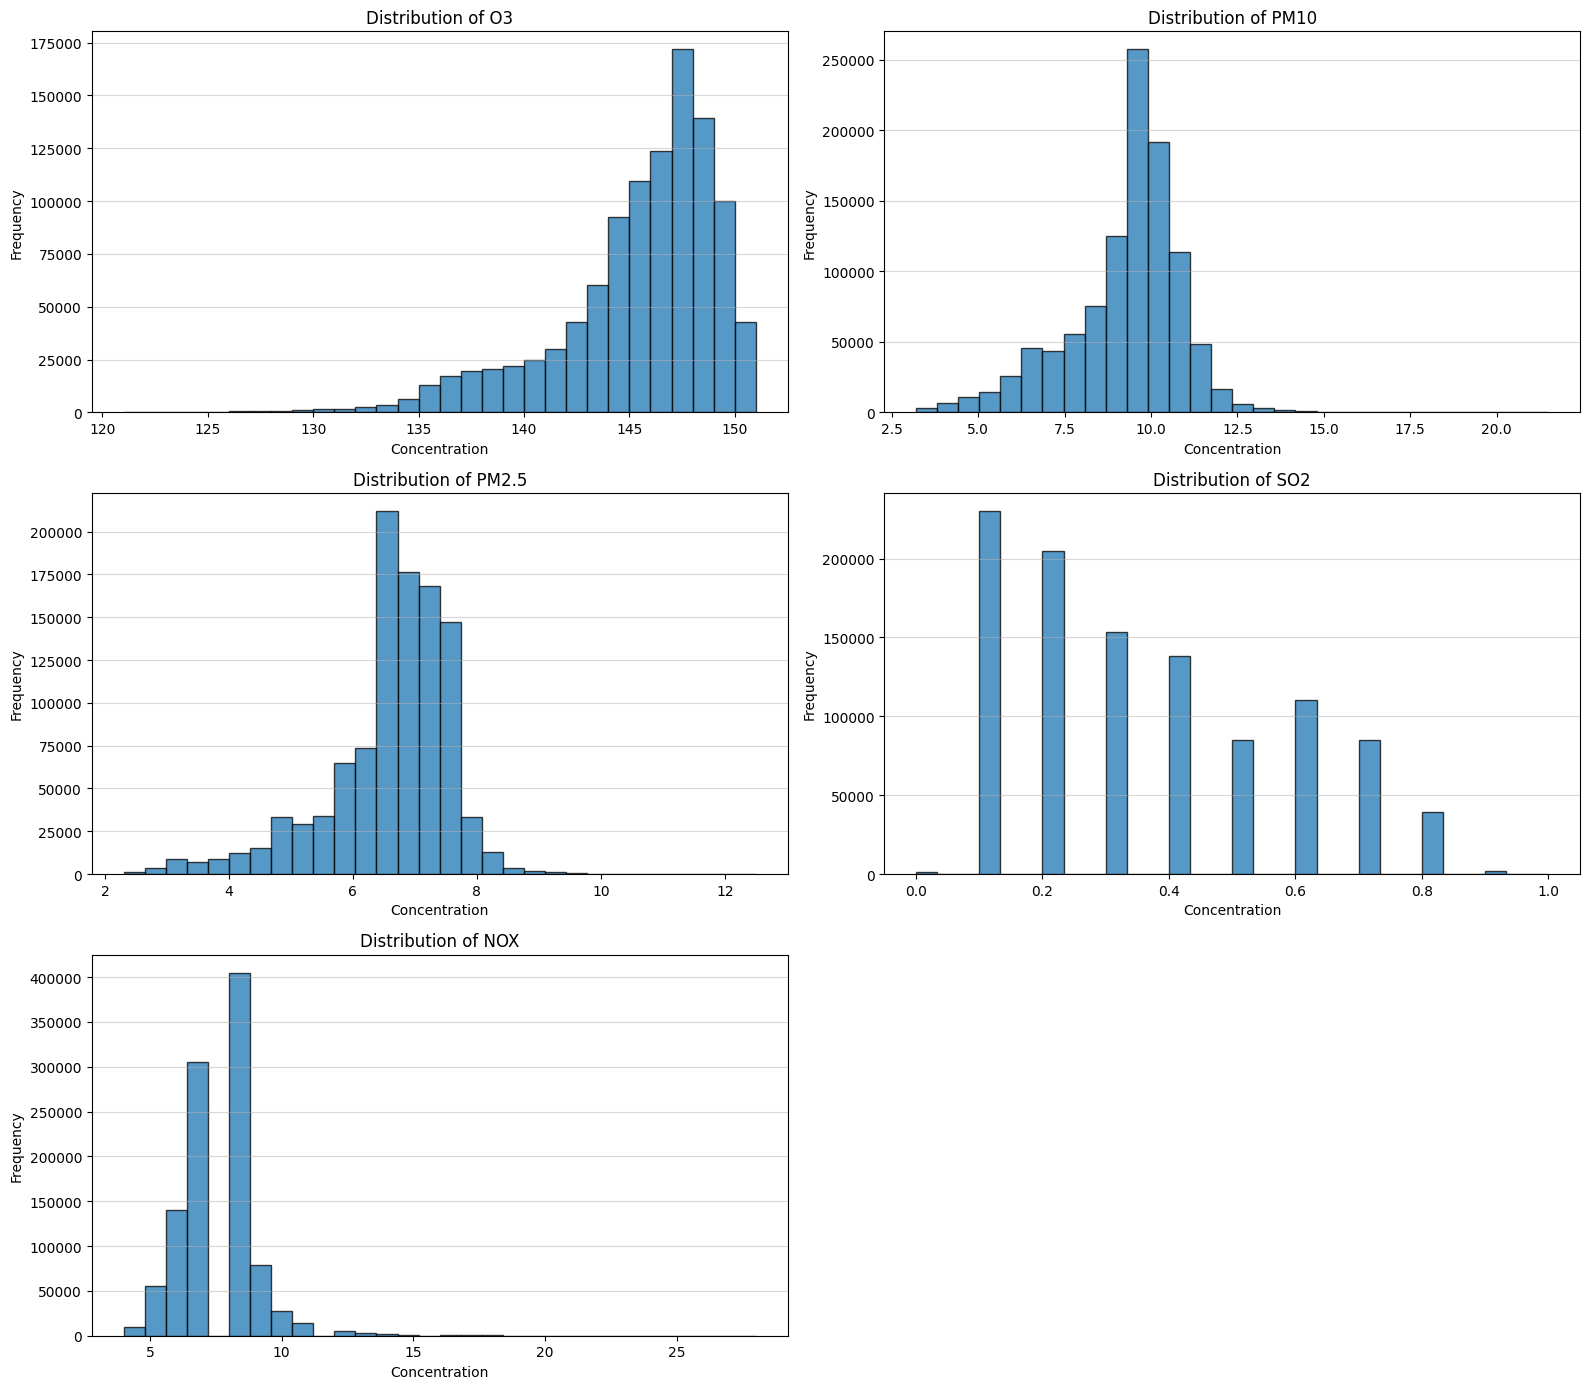

In [12]:
# Define the pollutants and include pm
pollutants = ["O3", "PM10", "PM2.5", "SO2", "NOX"]

# Create a figure with 5 histograms

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

#This line creates a figure containing 3 rows and 2 columns of subplots.
#So in total 6 separate plotting areas. The rest is just size.

axes = axes.flatten()

#this converts the two-dimensional arrangement of axes
#into a one-dimensional array, we need this for using enumerate more easily
#it could be done without flaten and instead of 3x2 I could use a 5 list, but
#3x2 gives us bigger plots.

#Plot each pollutant in its corresponding subplot

for i, pollutant in enumerate(pollutants):
    values = df[pollutant]

# Plot histogram
    axes[i].hist(values, bins=30, edgecolor="black", alpha=0.75)

    # Add labels and title
    axes[i].set_title(f"Distribution of {pollutant}")
    axes[i].set_xlabel("Concentration")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis="y", alpha=0.5)

# Hide any unused subplots (we have 5 pollutants but 6 subplots)
#It would work without but looks neater that way.
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

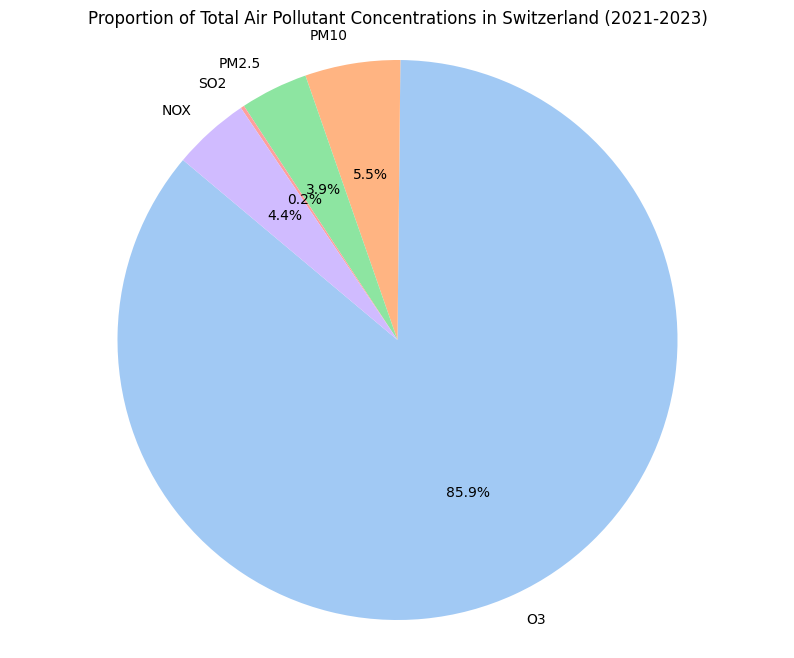

In [13]:
# Calculate the total sum of each pollutant to determine its proportion in the air
total_amounts = df[pollutants].sum()

# Create a pie chart
plt.figure(figsize=(10, 8))
plt.pie(
    total_amounts,
    labels=pollutants,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette("pastel")
)

plt.title("Proportion of Total Air Pollutant Concentrations in Switzerland (2021-2023)")
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

After the histograms I would like to plot some boxplots to compare the distributions of the five pollutants.
Why? To find out which pollutants have the greatest spread and which one has the most extreme observations. It will let us compare distributions and identify outliers.

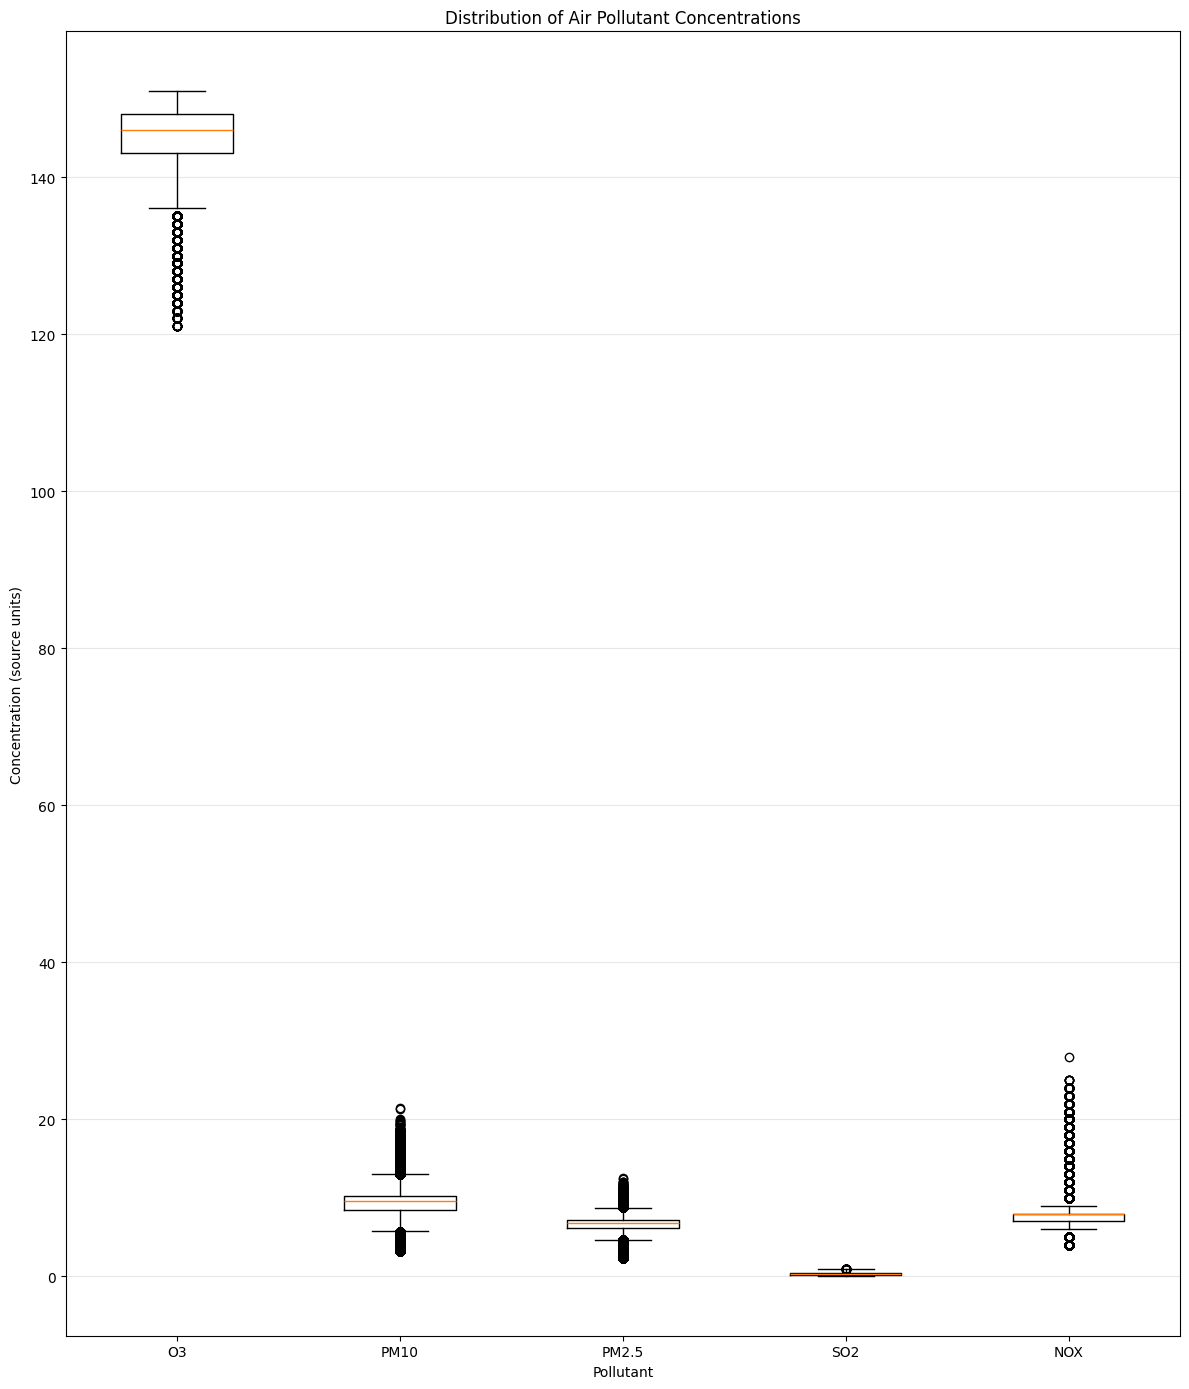

In [14]:
# Extract the data for the five pollutants
data = [df[pollutant] for pollutant in pollutants]

# Create the boxplots
fig, ax = plt.subplots(figsize=(12, 14))

ax.boxplot(data, tick_labels=pollutants)

ax.set_title("Distribution of Air Pollutant Concentrations")
ax.set_xlabel("Pollutant")
ax.set_ylabel("Concentration (source units)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


One important detail: the standard boxplot uses a single vertical axis for pollutants with different numerical concentration scales. O3 therefore dominates the graph, making the distributions of the other four pollutants harder to compare visually.

Also keep in mind that many outliers may simply reflect the large size of my dataset; they are not automatically measurement errors.

To fix part of it and actually be able to compare the relative spread of all five pollutants, I can use a logarithmic y-axis, provided the values are strictly positive, which they are. (A logarithmic scale cannot display zero or negative values).

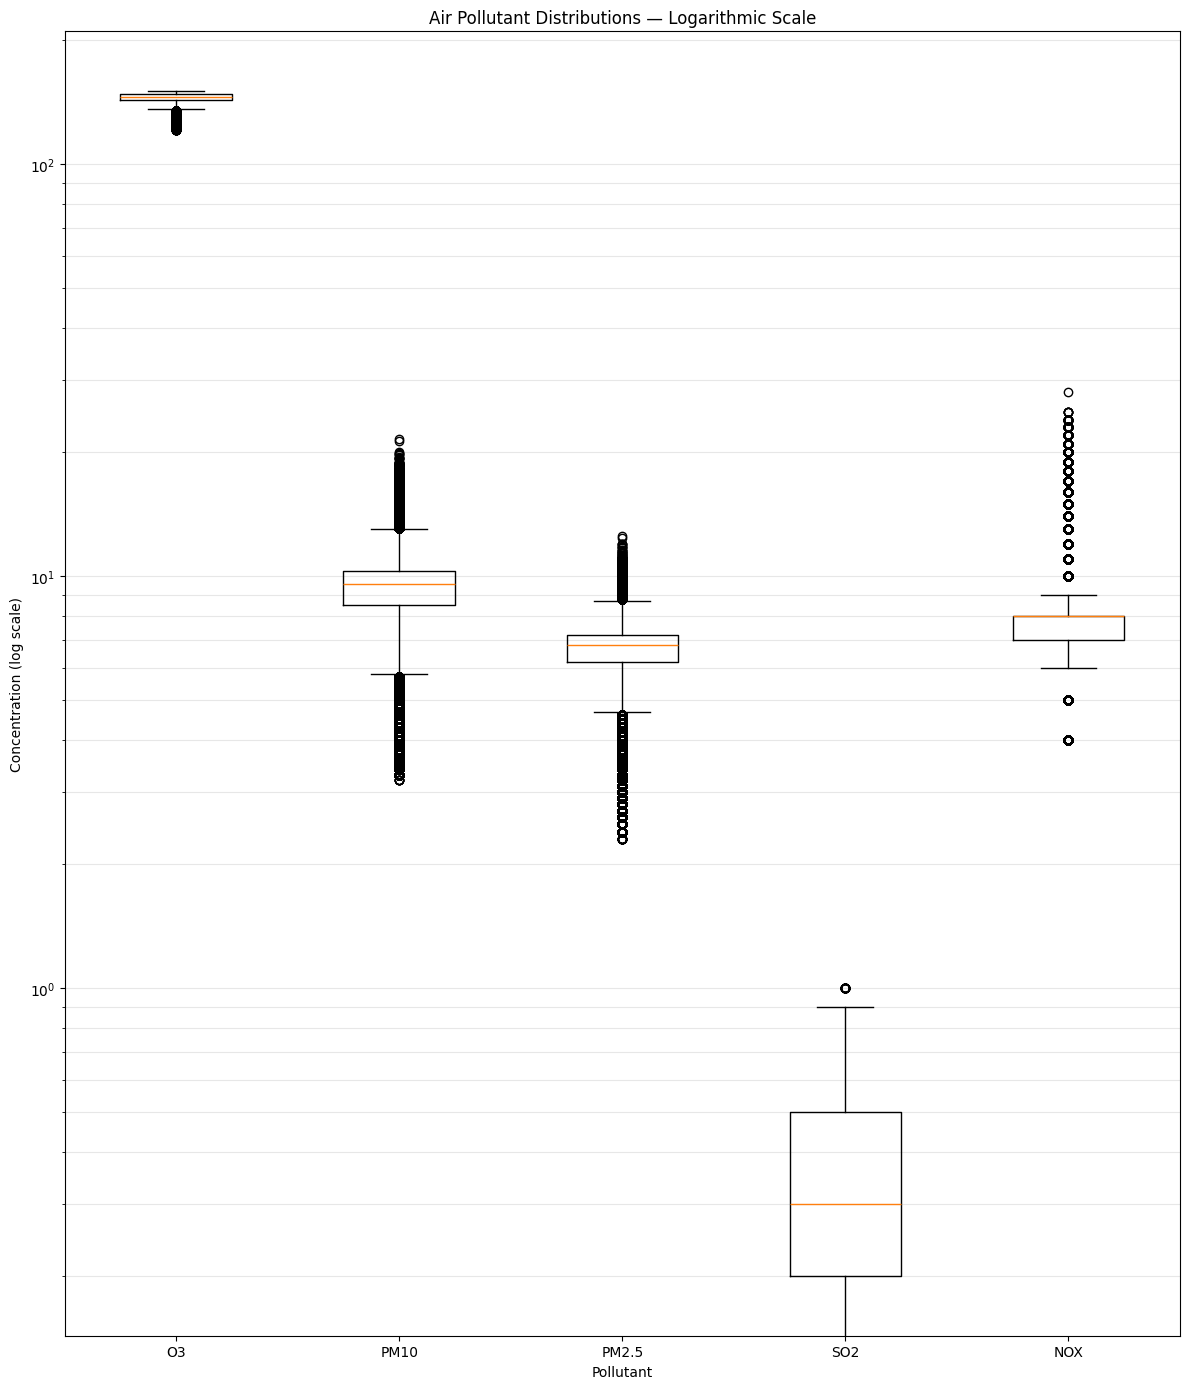

In [15]:
fig, ax = plt.subplots(figsize=(12, 14))

ax.boxplot(
    [df[p] for p in pollutants],
    tick_labels=pollutants
)

ax.set_yscale("log")
ax.set_title("Air Pollutant Distributions — Logarithmic Scale")
ax.set_xlabel("Pollutant")
ax.set_ylabel("Concentration (log scale)")
ax.grid(axis="y", alpha=0.3, which="both")

plt.tight_layout()
plt.show()

Now we get into the Module 2 part since we need statistics to be able to interpret this barplot.

So now let's calculate the statistics alongside the boxplots. This makes it easier to identify which pollutants have the greatest spread and highest extreme values.

In [16]:
stats = df[pollutants].describe().T

stats["variance"] = df[pollutants].var()
stats["range"] = stats["max"] - stats["min"]
stats["IQR"] = stats["75%"] - stats["25%"] #Interquartile Range = IQR (Spread of the central 50%)
stats["skewness"] = df[pollutants].skew() #skewness = Whether a distribution has a longer tail on one side
stats["kurtosis"] = df[pollutants].kurtosis() #tells us if the distribution looks like a bell curve

display(stats.round(3))

,count,mean,std,min,25%,50%,75%,max,variance,range,IQR,skewness,kurtosis
O3,1048575.0,144.944,3.897,121.0,143.0,146.0,148.0,151.0,15.190,30.0,5.0,-1.373,2.144
PM10,1048575.0,9.272,1.645,3.2,8.5,9.6,10.3,21.5,2.706,18.3,1.8,-0.732,1.123
PM2.5,1048575.0,6.593,0.993,2.3,6.2,6.8,7.2,12.5,0.986,10.2,1.0,-1.255,2.249
SO2,1048575.0,0.349,0.213,0.0,0.2,0.3,0.5,1.0,0.045,1.0,0.3,0.524,-0.883
NOX,1048575.0,7.485,1.398,4.0,7.0,8.0,8.0,28.0,1.953,24.0,1.0,1.579,11.241


Keep in mind: For skewness, a positive value generally indicates a longer right tail (skew > 0 means leftskewed), while a negative value indicates a longer left tail (skew < 0 means rightskewed). Values near zero indicate approximate symmetry. Those calculations confirm our skewness findings in the histogramms above.

For kurtosis k < 0 means the peak is narrow and for k > 0 the peak is broad.

Calculating the limits for every pollutant:

In [17]:
for pollutant in pollutants:
    q1 = df[pollutant].quantile(0.25)
    q3 = df[pollutant].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers = df[
        (df[pollutant] < lower_limit) |
        (df[pollutant] > upper_limit)
    ][pollutant]

    print(f"{pollutant}:")
    print(f"  Lower limit: {lower_limit:.2f}")
    print(f"  Upper limit: {upper_limit:.2f}")
    print(f"  Potential outliers: {len(outliers):,}")
    print()

O3:
  Lower limit: 135.50
  Upper limit: 155.50
  Potential outliers: 32,675

PM10:
  Lower limit: 5.80
  Upper limit: 13.00
  Potential outliers: 45,797

PM2.5:
  Lower limit: 4.70
  Upper limit: 8.70
  Potential outliers: 60,397

SO2:
  Lower limit: -0.25
  Upper limit: 0.95
  Potential outliers: 38

NOX:
  Lower limit: 5.50
  Upper limit: 9.50
  Potential outliers: 119,520



Interpretation of the plot and calculations

# What the boxplot reveals
**O3 (ozone)**

The central box is relatively compact, with a median around 146. There are many potential outliers below the lower whisker, but none above the upper whisker. This agrees with your outlier table: 32,675 low outliers and zero high outliers.
It is right skewed.



**PM10**

The box is relatively narrow, but there are potential outliers both below and above it. The high outliers extend to 21.5, substantially above the upper whisker. This suggests that some observations are much higher than the central range. It is rightskewed.



**PM2.5**

The central 50% of observations is concentrated around 6.2–7.2. There are potential outliers on both sides, especially below the lower whisker. The upper outliers reach 12.5. It is also rightskewed.



**SO2 (sulfur dioxide)**

The box is extremely compressed near zero compared with the other pollutants. Only 38 observations are classified as potential outliers, all on the high side. The maximum is 1.0, just above the upper limit of 0.95. It is quite evenly distributed with a slight leftskew.



**NOX (nitrogen oxides)**

The box is compact, but many potential outliers extend above and below the whiskers. The upper observations reach 28.0, compared with a median of 8.0. NOX has the largest total number of potential outliers: 119,520. It is leftskewed.


# What can we conclude?
These results support three main conclusions:
- The central distributions are relatively concentrated for several pollutants, as indicated by their IQRs.
- NOX has the largest number of potential outliers, followed by PM2.5 and PM10.
- The outlier patterns differ between pollutants. O3 has low-side outliers only, SO2 has very few high-side outliers, and PM10, PM2.5 and NOX have outliers on both sides.

Keeping in mind that these are potential statistical outliers, not necessarily errors. They may represent local pollution peaks, unusual conditions, or data-quality issues.

To have a nice overwiev of our outliers and IQR and the median all in one table, we can do the follwoing. It summarises the boxplot, text and table from above:

In [18]:
import pandas as pd

pollutants = ["O3", "PM10", "PM2.5", "SO2", "NOX"]

results = []
n = len(df)

for pollutant in pollutants:
    q1 = df[pollutant].quantile(0.25)
    median = df[pollutant].median()
    q3 = df[pollutant].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    below = df[pollutant] < lower_limit
    above = df[pollutant] > upper_limit
    total_outliers = int((below | above).sum())

    results.append({
        "Pollutant": pollutant,
        "Q1": q1,
        "Median": median,
        "Q3": q3,
        "IQR": iqr,
        "Lower limit": lower_limit,
        "Upper limit": upper_limit,
        "Low outliers": int(below.sum()),
        "High outliers": int(above.sum()),
        "Total outliers": total_outliers,
        "Highest observation": df[pollutant].max(),
        "Outliers (%)": 100 * total_outliers / n
    })

outlier_summary = pd.DataFrame(results).set_index("Pollutant")

display(outlier_summary.round(3))

,Q1,Median,Q3,IQR,Lower limit,Upper limit,Low outliers,High outliers,Total outliers,Highest observation,Outliers (%)
Pollutant,,,,,,,,,,,
O3,143.0,146.0,148.0,5.0,135.50,155.50,32675,0,32675,151.0,3.116
PM10,8.5,9.6,10.3,1.8,5.80,13.00,39353,6444,45797,21.5,4.368
PM2.5,6.2,6.8,7.2,1.0,4.70,8.70,56578,3819,60397,12.5,5.760
SO2,0.2,0.3,0.5,0.3,-0.25,0.95,0,38,38,1.0,0.004
NOX,7.0,8.0,8.0,1.0,5.50,9.50,64950,54570,119520,28.0,11.398


This adds an important perspective: what proportion of observations are classified as potential outliers?

A high proportion can occur because the distribution is strongly skewed, has several clusters, or has a narrow IQR relative to its tails. It does not necessarily indicate poor data quality. And as we found out previously my data is very skewed.

Hence I will not automatically delete these observations.

# 10 highest pollutant concentrations

If we wanted to observe where the 10 highest pollutant concentrations for each pollutant occour, we can do the follwoing:

In [19]:
for pollutant in pollutants:
    q1 = df[pollutant].quantile(0.25)
    q3 = df[pollutant].quantile(0.75)
    iqr = q3 - q1
    upper_limit = q3 + 1.5 * iqr

    high_values = df.loc[
        df[pollutant] > upper_limit,
        ["Longitude", "Latitude", pollutant]
    ].sort_values(
        by=pollutant,
        ascending=False
    ).head(10)

    print(f"\nTop 10 high outliers for {pollutant}:")
    display(high_values)    #O3 has no high outliers, so the table will be empty


Top 10 high outliers for O3:


,Longitude,Latitude,O3



Top 10 high outliers for PM10:


,Longitude,Latitude,PM10
393592,2731250,1252250,21.5
395643,2731350,1252150,21.3
164568,2622450,1265350,20.0
131884,2735450,1267750,19.9
161535,2621850,1265550,19.8
163050,2622150,1265450,19.8
305926,2718450,1256850,19.7
163051,2622250,1265450,19.5
161534,2621750,1265550,19.4
391542,2730950,1252350,19.4



Top 10 high outliers for PM2.5:


,Longitude,Latitude,PM2.5
393592,2731250,1252250,12.5
395643,2731350,1252150,12.4
161535,2621850,1265550,12.0
164568,2622450,1265350,12.0
309420,2707750,1256650,12.0
163050,2622150,1265450,11.9
309419,2707650,1256650,11.8
163051,2622250,1265450,11.8
311228,2708250,1256550,11.8
161534,2621750,1265550,11.7



Top 10 high outliers for SO2:


,Longitude,Latitude,SO2
123428,2752150,1268450,1.0
123429,2752250,1268450,1.0
123430,2752350,1268450,1.0
124654,2752150,1268350,1.0
124655,2752250,1268350,1.0
124656,2752350,1268350,1.0
124657,2752450,1268350,1.0
125885,2752550,1268250,1.0
125886,2752650,1268250,1.0
1002219,2658650,1221450,1.0



Top 10 high outliers for NOX:


,Longitude,Latitude,NOX
549319,2581650,1244550,28
738624,2573850,1234750,25
547859,2627750,1244650,25
448802,2665650,1249550,25
546399,2673850,1244750,25
550779,2727650,1244550,25
232572,2617550,1260950,24
233601,2720450,1260950,24
450261,2603350,1249450,24
451721,2749350,1249450,24


We have many outliers hence is might be a good idea to compare the usual percentiles with the high ones such as the 99th percentile. It is the threshold at or below which approximately 99% of observations fall.

It gives us a more robust picture of unusually high values than the maximum alone. The 99th percentile is not, however, a regulatory or health-based threshold.

# Let's examine upper-tail concentrations

In [20]:
percentile_levels = [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]

percentile_table = df[pollutants].quantile(percentile_levels).T
percentile_table.columns = [
    "50th", "75th", "90th", "95th", "99th", "99.9th"
]

display(percentile_table.round(3))

,50th,75th,90th,95th,99th,99.9th
O3,146.0,148.0,149.0,149.0,150.0,151.0
PM10,9.6,10.3,11.0,11.4,12.5,14.9
PM2.5,6.8,7.2,7.5,7.8,8.3,9.4
SO2,0.3,0.5,0.7,0.7,0.8,0.9
NOX,8.0,8.0,9.0,10.0,12.0,18.0


**These values reveal several interesting patterns.**

**O3 — relatively concentrated distribution**

The median is 146.0, and the 99.9th percentile is 151.0. The difference is only 5.0.

This suggests that the upper end of the O3 distribution is relatively concentrated compared with the other pollutants' numerical percentile differences. This agrees with our earlier boxplot, which showed many low outliers but no high outliers under the IQR rule.

**PM10 — a longer upper tail**

The median is 9.6, while the 99.9th percentile is 14.9.
The upper tail extends noticeably above the median, indicating that a small fraction of observations have substantially higher PM10 concentrations than typical observations.

**PM2.5 — a more moderate upper-tail increase**

The median is 6.8, compared with 9.4 at the 99.9th percentile.
The upper percentiles increase progressively, indicating elevated values in the upper tail.
(However, the absolute differences should not be compared directly with other pollutants unless their units and scales are comparable.)

**SO2 — most observations are at relatively low numerical values**

The median is 0.3, and the 99.9th percentile is 0.9.
Most observations are concentrated toward the lower end of the observed SO2 distribution, with a small upper tail. This is consistent with the relatively small number of potential outliers we calculated earlier.

**NOX — the most pronounced upper-tail increase**

The median is 8.0, the 99th percentile is 12.0, and the 99.9th percentile is 18.0.
This is the most pronounced upper-tail increase in the table in absolute numerical terms. It is consistent with our earlier findings that NOX has many potential outliers and a maximum of 28.0.

# What does the table tell us overall?


*   The central and upper portions of the distributions differ.
Some pollutants have a relatively small numerical gap between the median and the 99.9th percentile, while others show a more pronounced increase.

*   NOX deserves further investigation
Its upper percentiles rise substantially, which is consistent with the high number of potential outliers in our earlier analysis.

*   Percentiles complement the boxplot
The boxplot identifies potential outliers according to a fixed statistical rule. Percentiles show how the upper tail progresses, without relying solely on the maximum value.

**Attention**: these comparisons describe numerical distributions. They do not establish which pollutant is most harmful, because that requires pollutant-specific health or regulatory reference values.



# Visualisation of the upper percentiles

The steepness of each line shows how quickly concentrations increase as you move toward the upper tail of that pollutant's distribution.

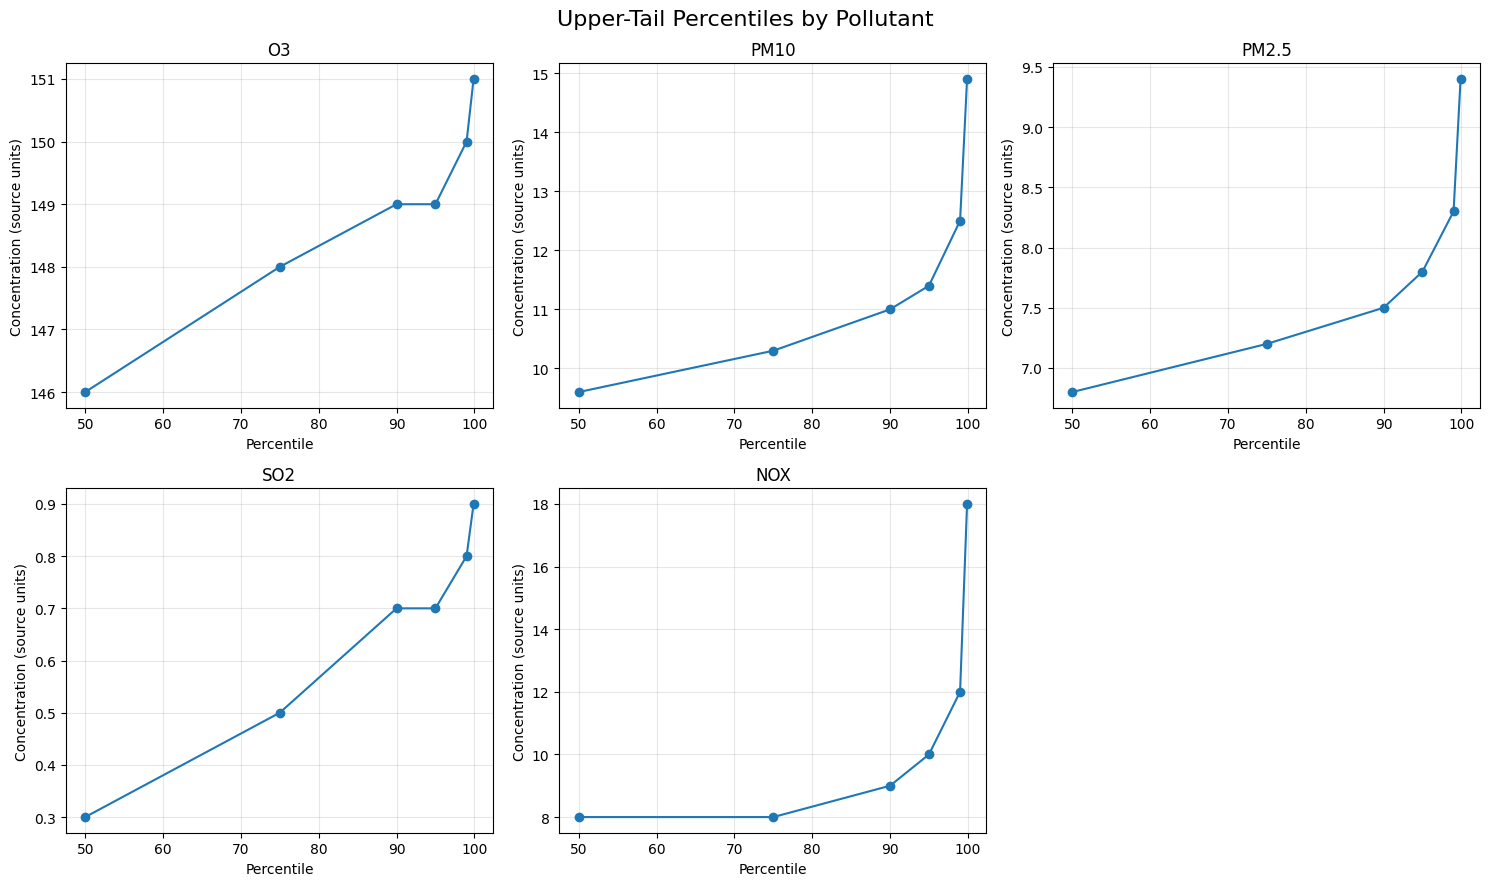

In [21]:
percentile_levels = [50, 75, 90, 95, 99, 99.9]

percentile_table = df[pollutants].quantile(
    [p / 100 for p in percentile_levels]
).T

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, pollutant in enumerate(pollutants):
    values = percentile_table.loc[pollutant].values

    axes[i].plot(
        percentile_levels,
        values,
        marker="o"
    )

    axes[i].set_title(pollutant)
    axes[i].set_xlabel("Percentile")
    axes[i].set_ylabel("Concentration (source units)")
    axes[i].grid(alpha=0.3)

fig.delaxes(axes[5])

fig.suptitle("Upper-Tail Percentiles by Pollutant", fontsize=16)
plt.tight_layout()
plt.show()

Now we want to examine the relationship between the pollutants

# Let's calculate the pearson correlation matrix
It examines if there is linear correlation.relationship

In [22]:
correlations = df[pollutants].corr(method="pearson")

display(correlations.round(3))

,O3,PM10,PM2.5,SO2,NOX
O3,1.000,0.244,0.238,0.026,-0.176
PM10,0.244,1.000,0.977,-0.077,-0.079
PM2.5,0.238,0.977,1.000,0.002,-0.053
SO2,0.026,-0.077,0.002,1.000,0.119
NOX,-0.176,-0.079,-0.053,0.119,1.000


Pearson correlation ranges from −1 to +1:

- Near +1: a strong positive linear relationship.

- Near −1: a strong negative linear relationship.

- Near 0: little or no linear relationship.

Correlation does not establish causation, and a low Pearson correlation does not rule out a nonlinear relationship.

# Visualize the correlations

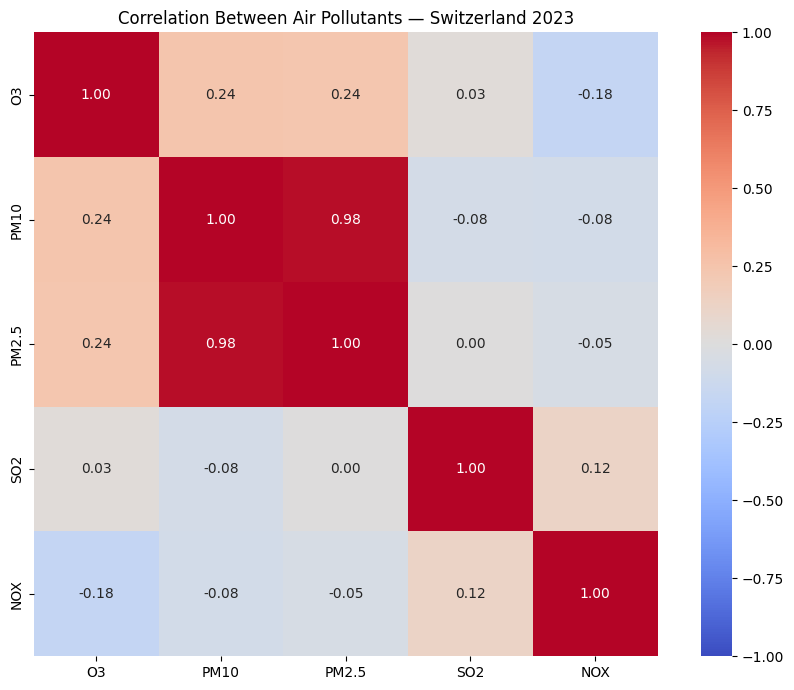

In [23]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlation Between Air Pollutants — Switzerland 2023")
plt.tight_layout()
plt.show()

**Here are the main findings in text:**

Pollutant pair	| Pearson \(r\) |	Interpretation

PM10 and PM2.5 |	0.977 |	Very strong positive correlation

O3 and PM10	| 0.244 | Weak positive correlation

O3 and PM2.5 |	0.238 |	Weak positive correlation

O3 and NOX	| −0.176 |	Weak negative correlation

SO2 and NOX |	0.119 |	Weak positive correlation

PM10 and NOX	| −0.079 | Very weak negative correlation

PM2.5 and NOX |	−0.053 | Very weak negative correlation

PM10 and SO2 |	−0.077 |	Very weak negative correlation

PM2.5 and SO2 | 0.002	| Essentially no linear correlation

O3 and SO2 | 0.026 |	Essentially no linear correlation

These descriptions concern the strength of the observed linear relationships. They do not yet tell us whether the correlations are statistically distinguishable from zero.

# The most important finding: PM10 and PM2.5

A correlation of r=0.977 indicates that observations with higher PM10 concentrations tend to have higher PM2.5 concentrations, and vice versa. The relationship is exceptionally strong and positive.

The squared correlation is

r2=0.9772≈0.955.

In a simple linear regression with an intercept, this means that approximately 95.5% of the observed variation in one pollutant can be accounted for by its linear relationship with the other in this dataset. It does not mean that PM10 causes 95.5% of PM2.5, or that the pollutants have the same concentrations.

Now I know that there are other relationships that I might uncover that may not be linear with using another correlation measure.

And I also do not know if the correlations are driven by extreme observations. The results may change when using a rank-based measure such as Spearman correlation. Hence it can be useful to compare the two methods before automatically removing outliers.

Let's do this.

# Let's calculate the Spearman correlation matrix

My distributions contain many potential outliers. The Spearman correlation is based on ranks, so it can help determine whether associations persist when the exact numerical distances between observations matter less.

In [24]:
correlations = df[pollutants].corr(method="spearman")

display(correlations.round(3))

,O3,PM10,PM2.5,SO2,NOX
O3,1.000,0.238,0.221,0.016,-0.237
PM10,0.238,1.000,0.964,-0.036,-0.068
PM2.5,0.221,0.964,1.000,0.078,-0.012
SO2,0.016,-0.036,0.078,1.000,0.149
NOX,-0.237,-0.068,-0.012,0.149,1.000


Spearman's rank correlation coefficient \(r_s\), measures how consistently two variables move in the same or opposite direction, based on their ranks.

Unlike Pearson correlation, which measures linear relationships, Spearman correlation measures monotonic relationships: whether higher values of one variable generally correspond to higher or lower values of the other.

The coefficient ranges from \(-1\) to \(+1\):
- Close to +1: Higher values of one pollutant tend to accompany higher values of the other.
- Close to 0: Little or no monotonic association.
- Close to −1: Higher values of one pollutant tend to accompany lower values of the other.

Here are the main relationships in your matrix:

Pollutant pair	| Spearman correlation | Interpretation

PM10 and PM2.5 |	0.964 |	Very strong positive association

O3 and NOX |	−0.237 |	Weak negative association

O3 and PM10 |	0.238 |	Weak positive association

O3 and PM2.5 |	0.221 |	Weak positive association

SO2 and NOX |	0.149 |	Weak positive association

PM10 and NOX |	−0.068 |	Very weak negative association

PM2.5 and NOX |	−0.012 |	Almost no monotonic association

PM2.5 and SO2 |	0.078 |	Very weak positive association

PM10 and SO2 |	−0.036 |	Almost no monotonic association

O3 and SO2 |	0.016 |	Almost no monotonic association

These descriptions concern the strength and direction of the observed relationships, not whether they are statistically significant.

# Visualize the correlations

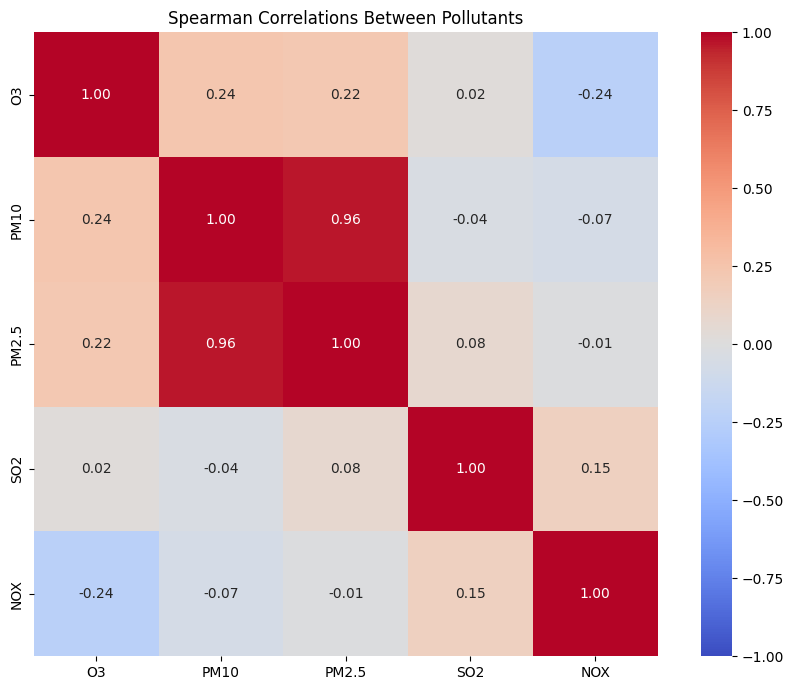

In [25]:
spearman_corr = df[pollutants].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Spearman Correlations Between Pollutants")
plt.tight_layout()
plt.show()

# The most important finding: PM10 and PM2.5

A correlation of r=0.964 indicates a very strong positive monotonic relationship: observations with higher PM10 concentrations generally also have higher PM2.5 concentrations.

The difference between the two coefficients is = 0.013, also very close. This suggests that the strong relationship is not merely an artefact of the exact concentration values or a few extreme observations. The pollutants also show a strong association when their values are converted into ranks.

However, the similarity of the coefficients does not prove that there are no outliers or that the relationship is perfectly linear. A scatterplot would help assess that.

# Other Findings

**O3 and NOX: a negative relationship**

The Spearman coefficient is \(-0.237\), indicating a weak negative monotonic association. Higher ozone observations tend to be associated with lower NOX observations to some extent.

This could be consistent with atmospheric chemistry: ozone and nitrogen oxides interact, and their relationship can vary with sunlight, location, time of day and other pollutants. The correlation matrix alone cannot establish the cause of the observed relationship.

**O3 and particulate matter: weak positive relationships**

- O3 and PM10: \(0.238\)

- O3 and PM2.5: \(0.221\)

These are weak positive associations. In the dataset, higher ozone values tend to accompany somewhat higher particulate-matter values, but the relationship is much less pronounced than the relationship between PM10 and PM2.5.

**SO2 and the other pollutants: mostly weak relationships**

The Spearman coefficients for SO2 range from \(-0.036\) to \(0.149\), except none of these indicate a strong monotonic association. This suggests that SO2 behaves differently from the other pollutants in this dataset, at least in terms of these pairwise relationships.

**Summary:**

Both measures identify PM10 and PM2.5 as by far the most strongly associated pair. The remaining relationships are comparatively weak.

**Disclaimner:** Neither correlation measure establishes causation, and neither coefficient by itself tells us whether the association is statistically distinguishable from zero.

# Is the PM10–PM2.5 association statistically distinguishable from zero?

This is the specific research question we want to answer. Let's formulate it as a hypothesis test:

    Null hypothesis (H0​): The population Pearson correlation between PM10 and PM2.5 is zero, ρ=0.

    Alternative hypothesis (H1​): The population Pearson correlation is not zero, ρ≠0.

I will use a significance level of alpha=0.05.

(This means that if the p-value is below 0.05, the null hypothesis is rejected in favor of a nonzero linear association, subject to the test's assumptions.)

Next step: obtain the correlation, p-value, confidence interval, and sample size.

# Pearson correlation test

In [26]:
from scipy.stats import pearsonr

# Select paired observations
data = df[["PM10", "PM2.5"]].dropna()

# Calculate Pearson correlation and p-value
r, p_value = pearsonr(data["PM10"], data["PM2.5"])

# Print results
print("PM10 and PM2.5: Pearson correlation test")
print("-----------------------------------------")
print(f"Number of observations: {len(data):,}")
print(f"Pearson correlation (r): {r:.6f}")
print(f"P-value: {p_value:.6e}")
print(f"Significance level: 0.05")

if p_value < 0.05:
    print("\nDecision: Reject the null hypothesis.")
    print("The association is statistically distinguishable from zero.")
else:
    print("\nDecision: Do not reject the null hypothesis.")
    print("There is insufficient evidence of a nonzero linear association.")

PM10 and PM2.5: Pearson correlation test
-----------------------------------------
Number of observations: 1,048,575
Pearson correlation (r): 0.977145
P-value: 0.000000e+00
Significance level: 0.05

Decision: Reject the null hypothesis.
The association is statistically distinguishable from zero.


**Pearson's \(r\):** measures the strength and direction of the linear association. A positive value means higher PM10 tends to occur alongside higher PM2.5; a negative value means they tend to vary in opposite directions.

**The p-value:** measures how incompatible the observed correlation is with the null hypothesis of zero population correlation, under the test's assumptions.

## Results of the Pearson correlation test

The results indicate that PM10 and PM2.5 are very strongly positively associated in the observed dataset. The test also reports overwhelming statistical evidence against a zero population Pearson correlation, assuming its inferential assumptions hold.

The correlation is not merely statistically significant; it is also very strong.

**Decision**: Reject the null hypothesis under the assumptions of the standard Pearson correlation test.

**Disclaimer**: The standard Pearson test assumes independent paired observations for its usual p-value calculation. Spatial dependence or repeated measurements can make the reported p-value overly optimistic

# Visual Analysis of the Association Between PM10 and PM2.5

With a large dataset, plotting every point can be slow and make the graph difficult to read. A hexbin plot shows where observations are concentrated.

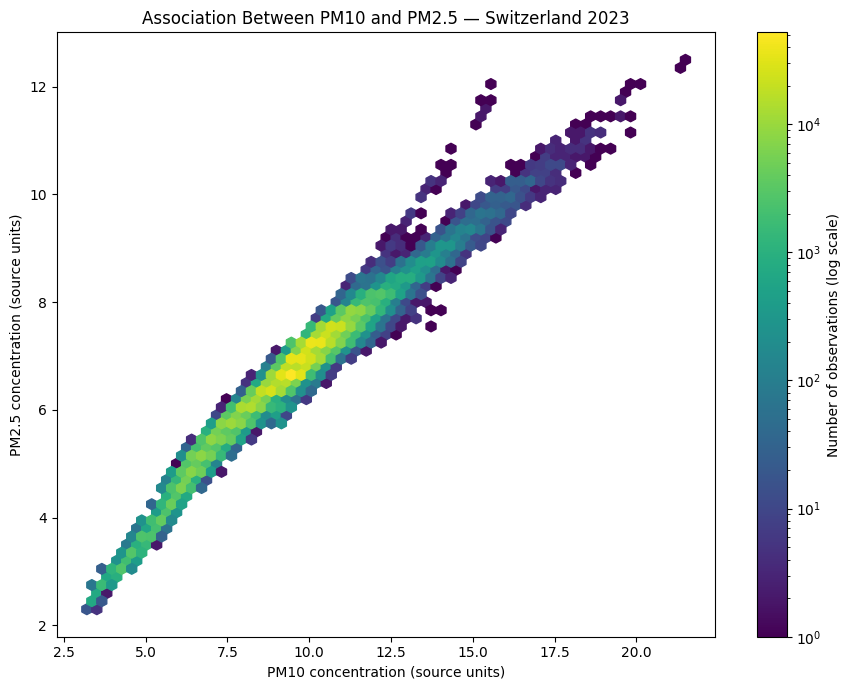

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.hexbin(
    data["PM10"],
    data["PM2.5"],
    gridsize=60,
    mincnt=1,
    bins="log"
)

plt.colorbar(label="Number of observations (log scale)")
plt.xlabel("PM10 concentration (source units)")
plt.ylabel("PM2.5 concentration (source units)")
plt.title("Association Between PM10 and PM2.5 — Switzerland 2023")

plt.tight_layout()
plt.show()

The hexbin plot shows a very strong positive association between PM10 and PM2.5 concentrations. The observations form a narrow, upward-sloping band, indicating that higher PM10 concentrations generally correspond to higher PM2.5 concentrations. The highest observation density occurs approximately around PM10 concentrations of 9–12 and PM2.5 concentrations of 6–8 source units.

This visual pattern is consistent with the Pearson correlation coefficient of 0.977145 and the Spearman rank correlation coefficient of 0.964. Although the association is very strong, the plotted relationship appears somewhat curved, suggesting that it may not be perfectly linear across the full concentration range. The plot therefore complements the correlation analysis but does not, by itself, establish statistical significance or causation.

**Next step:** Add a regression line to the plot and examine the residuals. This will help to distinguish a strong association from a relationship that is also well described by a linear model.
Let's fit a linear regression model:

# Linear Regression

Linear regression: PM2.5 predicted from PM10
Intercept: 1.1258
Slope:     0.5897
R-squared: 0.9548
RMSE:      0.2110
MAE:       0.1700


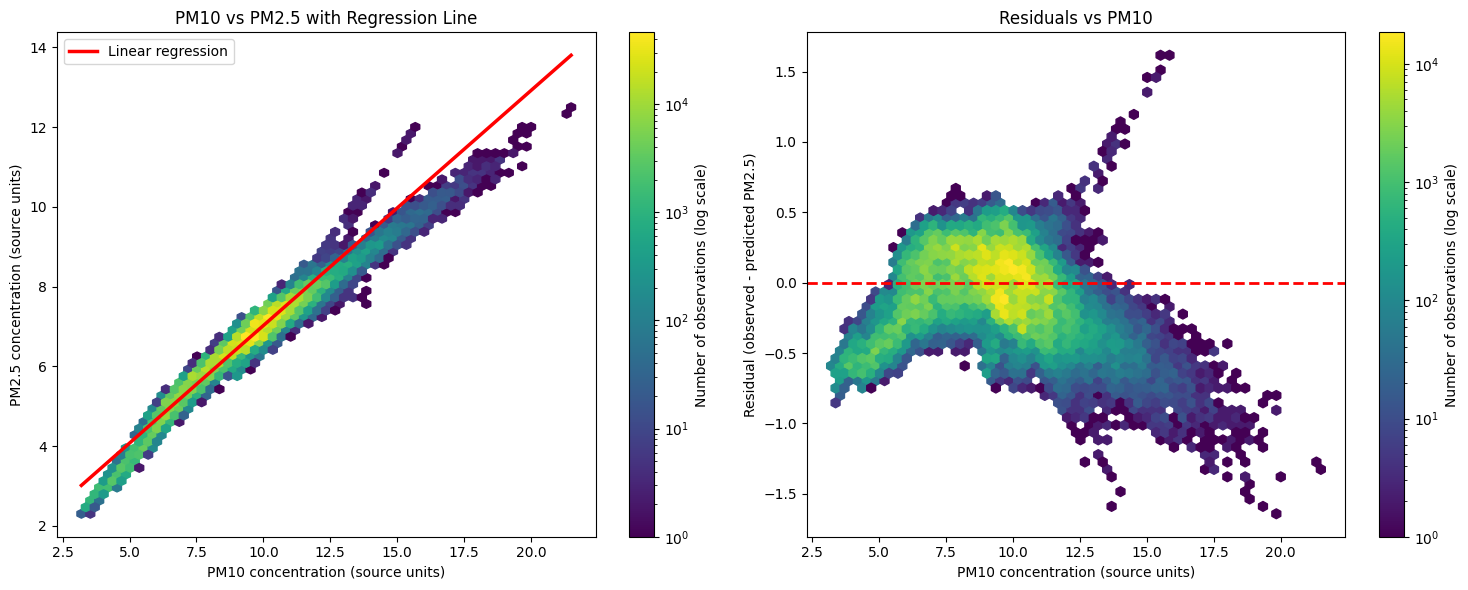

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Select the two pollutants
x = df["PM10"].to_numpy()
y = df["PM2.5"].to_numpy()

# Fit the linear regression model
X = x.reshape(-1, 1)
model = LinearRegression()
model.fit(X, y)

# Predicted PM2.5 values and residuals
y_pred = model.predict(X)
residuals = y - y_pred

# Calculate model diagnostics
r2 = r2_score(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))
mae = mean_absolute_error(y, y_pred)

print("Linear regression: PM2.5 predicted from PM10")
print(f"Intercept: {model.intercept_:.4f}")
print(f"Slope:     {model.coef_[0]:.4f}")
print(f"R-squared: {r2:.4f}")
print(f"RMSE:      {rmse:.4f}")
print(f"MAE:       {mae:.4f}")

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Hexbin plot with regression line
hb = axes[0].hexbin(
    x, y,
    gridsize=55,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

x_line = np.linspace(x.min(), x.max(), 300)
y_line = model.predict(x_line.reshape(-1, 1))

axes[0].plot(
    x_line, y_line,
    color="red",
    linewidth=2.5,
    label="Linear regression"
)

axes[0].set_title("PM10 vs PM2.5 with Regression Line")
axes[0].set_xlabel("PM10 concentration (source units)")
axes[0].set_ylabel("PM2.5 concentration (source units)")
axes[0].legend()

cbar = fig.colorbar(hb, ax=axes[0])
cbar.set_label("Number of observations (log scale)")

# Plot 2: Residuals against PM10
hb2 = axes[1].hexbin(
    x, residuals,
    gridsize=55,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

axes[1].axhline(0, color="red", linestyle="--", linewidth=2)
axes[1].set_title("Residuals vs PM10")
axes[1].set_xlabel("PM10 concentration (source units)")
axes[1].set_ylabel("Residual (observed - predicted PM2.5)")

cbar2 = fig.colorbar(hb2, ax=axes[1])
cbar2.set_label("Number of observations (log scale)")

plt.tight_layout()
plt.show()

# Results of the Linear Regression

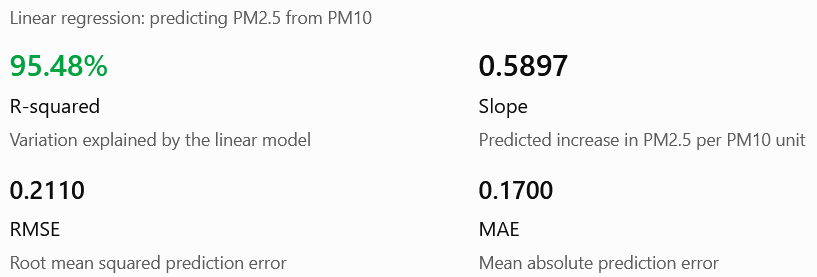

The fitted regression equation looks like
\[
\widehat{\mathrm{PM2.5}}
=1.1258+0.5897\,\mathrm{PM10}.
\] (idk how to make math stuff!)

This means that, according to the fitted model, a one-unit increase in PM10 corresponds to an average predicted increase of approximately 0.59 units in PM2.5.

The \(R^2\) value of 0.9548 means that the linear model accounts for about 95.48% of the observed variation in PM2.5 in this dataset. That is a very high proportion.

However, a high \(R^2\) alone does not establish that the model is appropriate across the full range of PM10 values.

**Summary**: the pollutants have a very strong association, but a straight line may not be the best functional description of that association.

Next step: compare linear and quadratic regression

# Stuff I might have to do later

What is still to do? Goal for M3 is to create a model that predicts the PM, to see this stay tuned for the next Jupiterotebook.

For the final project I would need to add a Swiss map to the dataset visialisation, geographic pollution map:
Plot Longitude and Latitude, using colour to represent the concentration of a pollutant.
- Answers: Where are pollution levels higher or lower?
- Best for: Discovering geographic hotspots and spatial patterns.
To identify the hotspots: rank grid cells by average pollutant concentration and examine the highest values.

Compare pollutants: create small-multiple maps and a correlation heatmap. A correlation heatmap would show the correlations between O3, PM10, PM2.5, SO2 and NOX.
- Answers: Which pollutants tend to increase or decrease together?
- Best for: Identifying relationships between pollutants.

Refine the maps: add Swiss borders or canton boundaries once the coordinate reference system has been confirmed.

And also, I have to fomulate a nice and clear Fragestellung, which I can answer.
Then for the final project I could extend the prediction model to the other 3 pollutants. At the end I need to put the whole text in a grammar correction programme.
For design purposes I could transfer all my text into LaTex to make it look nice.